In [2]:
print("test kernel")

test kernel


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from baseframework import datahandler
from baseframework.offline_clustering.adjacency import adjacency_clustering

[[0.68479944 0.24851561]
 [0.3001912  0.76540947]
 [0.61570754 0.61467317]
 [0.70614274 0.32031927]
 [0.26602823 0.69761609]]
[0 1 2 0 1]


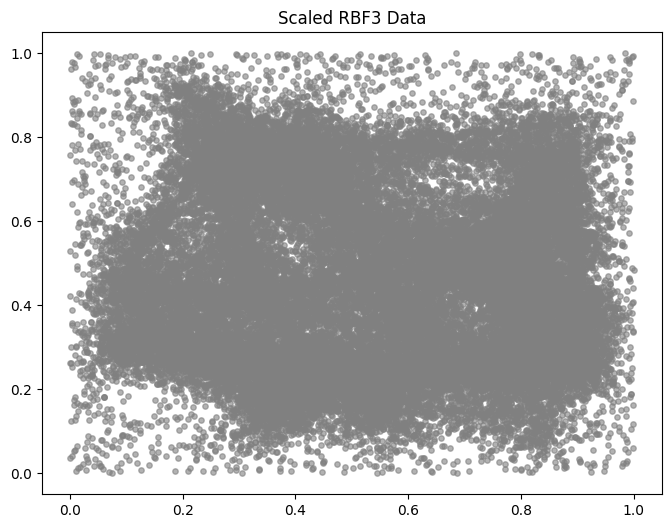

In [4]:
import sys
sys.path.insert(0, '/Users/felix/Desktop/Local/Uni/SoSe26/Stream Clustering/dstream-hajuj/baseframework')
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

# 1. Load the data using the handler
# This gives us the scaled features (X) and the ground truth labels (y)
X, y_true = datahandler.load_data("rbf3")
print(X[0:5])
print(y_true[0:5])

# Plot it quickly 
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=15, c='gray', alpha=0.6)
plt.title("Scaled RBF3 Data")
plt.show()

In [5]:
print(X[0])
print(X[0][0])


[0.68479944 0.24851561]
0.6847994357638937


Strengths and Weaknesses

Strengths:
• Efficiency: It is relatively efficient with a time complexity of $O(tkn)$ (where $t$ is iterations, $k$ is the number of clusters, and $n$ is the number of objects).
• Simplicity: It is known for its easy implementation.

Weaknesses:
• The $k$ problem: You are forced to specify $k$, the number of clusters, in advance. If you guess wrong, the clustering will be poor.

• Shape limitations: Clusters are forced into convex space partitions (known as Voronoi Cells). This means it struggles with any data that isn't roughly spherical.

• Sensitivity: It is highly sensitive to noisy data and outliers. Because it uses the "mean" to find the center, a single extreme outlier can drag the centroid far away from the true dense group.

• Initial luck: The final result and the runtime strongly depend on the initial random placement of the centroids; it often gets stuck in a "local optimum" (a result that looks mathematically okay to the algorithm but isn't the best possible grouping)

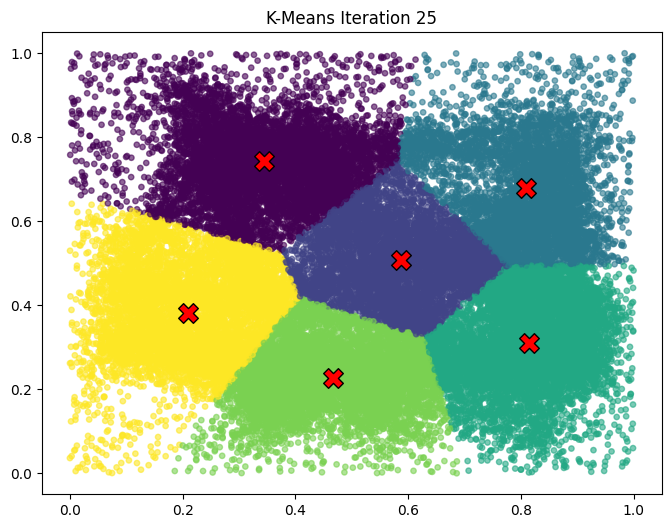

In [ ]:

def run_interactive_kmeans(X, k, max_iters=10):
    # TODO: 1. Initialization
    # Randomly select 'k' points from X to be your initial centroids.
    centroids = X[np.random.choice(X.shape[0], size=k, replace=False), :]
    print("Centroids: ", centroids)
    #centroids = X[np.random.randint(X.shape[0], size=k), :]

    
    for i in range(max_iters):
        # TODO: 2. Assignment Phase
        # Calculate the distance between EVERY point in X and EVERY centroid.
        # Assign each point to the index of the closest centroid.
        # 'labels' should be an array of length len(X) containing integers from 0 to k-1.
        distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
        labels = np.argmin(distances, axis=1)

        
        # --- Visualization Step ---
        clear_output(wait=True)
        plt.figure(figsize=(8, 6))
        plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=15, alpha=0.6)
        plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, edgecolors='black')
        plt.title(f"K-Means Iteration {i+1}")
        plt.show()
        time.sleep(1)
        # --------------------------------------------------
        
        # TODO: 3. Update Phase
        # For each cluster (0 to k-1), find all points assigned to it.
        # Calculate the mean (average) of those points' X and Y coordinates.
        # Update the centroid to this new mean position.
        old_centroids = centroids.copy()
        for j in range(k):
            # 1. Find all points assigned to cluster 'j'
            cluster_points = X[labels == j]
            
            # 2. Calculate the mean of those points and update the centroid
            # avoid dividing by zero!
            if len(cluster_points) > 0:
                # axis=0 means "calculate the average down the columns" (so you get mean x and mean y)
                centroids[j] = np.mean(cluster_points, axis=0)
        
        
        # Check for convergence (if centroids stop moving, we are done early)
        if np.all(centroids == old_centroids):
            print(f"Converged after {i+1} iterations!")
            break
            


# Run your function!
run_interactive_kmeans(X, k=6, max_iters=25)

In [ ]:
##### DBSCAN - Density Based Spatial Clustering of Applications with Noise
# instead of looking for the "center" of a cluster, like in K-means, DBSCAN basic idea is that clusters are simply dense regions in the data space
# which are seperated by regions of low density!

# the core concept - Density and parameters
# in order to define a "dense region", DBSCAN relies on two parameters instead of k:
#       - epsilon: the radius defining the neighborhood around a given point
#       - MinPts: the minimum number of points that must exist within that epsilon-neighborhood to consider it dense

# based on the epsilon and MinPts, DBSCAN categorizes every single point in the dataset into one of these 3 distinct classes:
#       - Core Point: A point that has at least MinPts within its epislon radium. these are considered to be the hearts of the cluster
#       - Border Point: A point that does not have MinPTS neighbors itself, but it falls within the epsilon radius of a Core Point. in other words it sits on the edge of a cluster
#       - Noise (Outlier): A point that is neither a Core point nor a border point. it is isolated in a low density region

# Algorithm:
# 1. It picks an unvisited point
# 2. If the point is a Core object, it starts a new cluster and collects all "density-reachable" objects (it checks the neighbors, and the neighbors of those neighbors, chaining them together until the density drops off)
# 3. If the point is not a Core object, it is temporarily (or permanently) assigned as Noise.
# 4. It repeats this until all points have been visited

# Strengths vs. Weaknesses:
# DBSCAN solves K-means 


